In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Load and clean
raw_df = pd.read_csv('/content/Dataset__SMR.csv')
raw_df.columns = [c.strip() for c in raw_df.columns]

# Add or keep only rows needed here
required_cols = [
    'F(mL/h)', 'T(C)', 'B(mT)', 'p(W)', 'TOS(h)', 'Delta_t(h)',
    'z_CH4_in', 'N_CH4_feed_cum(mol)', 'E_cum(kWh)', 'MoH_interval(kg)'
]
raw_df = raw_df.dropna(subset=required_cols).copy()


# 2. Feature engineering
raw_df['TOS_mid(h)'] = raw_df['TOS(h)'] - 0.5 * raw_df['Delta_t(h)']

# Primary target: interval H2 production rate [g/h]
raw_df['rH2_interval(g/h)'] = 1000.0 * raw_df['MoH_interval(kg)'] / raw_df['Delta_t(h)']

# Positive target transform
eps = 1e-12
raw_df['log_rH2'] = np.log(np.clip(raw_df['rH2_interval(g/h)'], eps, None))


# 3. Aggregate exact duplicate operating points
group_cols = ['F(mL/h)', 'T(C)', 'B(mT)', 'p(W)', 'TOS(h)', 'Delta_t(h)', 'TOS_mid(h)', 'z_CH4_in']

agg_df = (
    raw_df.groupby(group_cols, as_index=False)
    .agg({
        'log_rH2': ['mean', 'std', 'count'],
        'MoH_interval(kg)': 'mean',
        'N_CH4_feed_cum(mol)': 'mean',
        'E_cum(kWh)': 'mean'
    })
)

agg_df.columns = [
    'F(mL/h)', 'T(C)', 'B(mT)', 'p(W)', 'TOS(h)', 'Delta_t(h)', 'TOS_mid(h)', 'z_CH4_in',
    'log_rH2_mean', 'log_rH2_std', 'rep_count',
    'MoH_interval_mean(kg)', 'N_CH4_feed_cum(mol)', 'E_cum(kWh)'
]

agg_df['log_rH2_std'] = agg_df['log_rH2_std'].fillna(0.0)


# 4. Encode features
#    Continuous: T(C), TOS_mid(h)
#    Categorical: F, B, p, Delta_t
continuous_cols = ['T(C)', 'TOS_mid(h)']
categorical_cols = ['F(mL/h)', 'B(mT)', 'p(W)', 'Delta_t(h)']

X_cont = agg_df[continuous_cols].copy()
X_cat = pd.get_dummies(agg_df[categorical_cols].astype(str), drop_first=False)

X_all = pd.concat([X_cont, X_cat], axis=1)
y_all = agg_df[['log_rH2_mean']].copy()


# 5. Data Split
X_train_raw, X_temp_raw, y_train_raw, y_temp_raw, train_meta, temp_meta = train_test_split(
    X_all, y_all, agg_df, test_size=0.30, random_state=42
)

X_val_raw, X_test_raw, y_val_raw, y_test_raw, val_meta, test_meta = train_test_split(
    X_temp_raw, y_temp_raw, temp_meta, test_size=0.50, random_state=42
)

# 6. Scale using training only
x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train_scaled = X_train_raw.copy()
X_val_scaled = X_val_raw.copy()
X_test_scaled = X_test_raw.copy()

X_train_scaled[continuous_cols] = x_scaler.fit_transform(X_train_raw[continuous_cols])
X_val_scaled[continuous_cols]   = x_scaler.transform(X_val_raw[continuous_cols])
X_test_scaled[continuous_cols]  = x_scaler.transform(X_test_raw[continuous_cols])

y_train_scaled = y_scaler.fit_transform(y_train_raw)
y_val_scaled   = y_scaler.transform(y_val_raw)
y_test_scaled  = y_scaler.transform(y_test_raw)

# Convert to numpy
X_train_scaled = X_train_scaled.values.astype(float)
X_val_scaled   = X_val_scaled.values.astype(float)
X_test_scaled  = X_test_scaled.values.astype(float)

y_train_scaled = y_train_scaled.astype(float)
y_val_scaled   = y_val_scaled.astype(float)
y_test_scaled  = y_test_scaled.astype(float)


# 7. Training-only bootstrap augmentation
#    with Gaussian noise on continuous features
#    scale = 2, 5, or 10

# Number of continuous feature columns (must match continuous_cols order in X_train_scaled)
# T(C) and TOS_mid(h) — columns 0 and 1
N_CONT_COLS = len(continuous_cols)
def augment_training_set(X_train, y_train, scale=5, noise_std=0.15, random_state=42):

    rng = np.random.default_rng(random_state)
    n = len(X_train)

    if scale <= 1:
        return X_train.copy(), y_train.copy()

    n_final = int(scale * n)

    # Bootstrap resampling
    idx = rng.integers(0, n, size=n_final)
    X_aug = X_train[idx].copy()
    y_aug = y_train[idx].copy()

    # Gaussian noise on continuous features only
    noise_X = rng.normal(loc=0.0, scale=noise_std, size=(n_final, N_CONT_COLS))
    X_aug[:, :N_CONT_COLS] += noise_X

    # Small Gaussian noise on target (log-space)
    noise_y = rng.normal(loc=0.0, scale=noise_std, size=y_aug.shape)
    y_aug += noise_y

    return X_aug, y_aug

# choose augmentation scale here
AUG_SCALE = 10  # try 2, 5, 10

X_train_aug, y_train_aug = augment_training_set(
    X_train_scaled, y_train_scaled, scale=AUG_SCALE, noise_std=0.15, random_state=42
)

print("Train:", X_train_aug.shape, y_train_aug.shape)
print("Val  :", X_val_scaled.shape, y_val_scaled.shape)
print("Test :", X_test_scaled.shape, y_test_scaled.shape)

Train: (590, 22) (590, 1)
Val  : (13, 22) (13, 1)
Test : (13, 22) (13, 1)


In [ ]:
### PRELIMINARY DATA ANALYSIS OF THE RAW DATASET ###

## Filtering Operating Data with MoH_interval(kg) > 0 and NAN from MoH_interval(kg) > 0 ##

df_operational = raw_df[(raw_df['MoH_interval(kg)'] > 0) & raw_df['SEC_cum(kWh/kgH2)'].notna()].copy()

# Convert 'SEC_cum(kWh/kgH2)' to numeric, coercing errors
df_operational['SEC_cum(kWh/kgH2)'] = pd.to_numeric(df_operational['SEC_cum(kWh/kgH2)'], errors='coerce')

# Drop rows where 'SEC(kWh/kg H2)' became NaN after coercion
df_operational.dropna(subset=['SEC_cum(kWh/kgH2)'], inplace=True)

## Carry Out Descriptive on the Raw Dataset SEC_cum(kWh/kgH2)', 'Y_H2_cum_feed(%)', 'MoH(g)')  ##
print("### 1. Descriptive Statistics of Derived Variables:\n ###")
desc_stats = df_operational[['SEC_cum(kWh/kgH2)', 'Y_H2_cum_feed(%)', 'MoH_interval(kg)']].describe()
print(desc_stats)
print("\n")

## Carry Out Correlation Analysis on the Raw Dataset for both Input and Output dataset:'p(W)', 'B(mT)', 'F(mL/h)', 'X(%)', 'TOS(h)','SEC(kWh/kg H2)', 'EI(kgCO2/kgH2)', 'VoH(L)', 'MoH(g)'  ##
correlation_cols = ['p(W)', 'B(mT)', 'F(mL/h)', 'TOS(h)', 'SEC_cum(kWh/kgH2)', 'Y_H2_cum_feed(%)', 'MoH_interval(kg)']
correlation_matrix = df_operational.dropna(subset=correlation_cols)[correlation_cols].corr(numeric_only=True)
print("### 2. Correlation Matrix of Key Parameters:\n ###")
print(correlation_matrix)
print("\n")

## Carry Out Binned Analysis of SEC by Magnetic Flux (B(mT)) ##
bins = [0, 10, 20, 30, 40, 50, 60]
labels = ['0-10mT', '11-20mT', '21-30mT', '31-40mT', '41-50mT', '51-60mT']
df_operational['B_Bin'] = pd.cut(df_operational['B(mT)'], bins=bins, labels=labels, right=True, include_lowest=True)
binned_sec_analysis = df_operational.groupby('B_Bin')['SEC_cum(kWh/kgH2)'].agg(['mean', 'median', 'min', 'max', 'count'])
print("### 3. Binned Analysis of SEC by Magnetic Flux (B(mT)):\n ###")
print(binned_sec_analysis)
print("\n")


### Identifying the Most Energy-Efficient (Lowest SEC) ROW in the Raw Dataset ###
if not df_operational.empty:
    optimal_row_sec = df_operational.loc[(df_operational['SEC_cum(kWh/kgH2)'].idxmin())]
    print("### 4. Most Energy-Efficient Operating Point (Lowest SEC):\n ###")
    print("The row representing the most energy-efficient operating point (lowest SEC) is:\n")
    print(optimal_row_sec[['p(W)', 'B(mT)', 'F(mL/h)', 'TOS(h)', 'MoH_interval(kg)', 'SEC_cum(kWh/kgH2)', 'Y_H2_cum_feed(%)']].to_markdown(index=True))
else:
    print("No operational data available (no MoH_interval(kg) > 0 or SEC is NaN). Cannot identify optimal point.")
print("\n")

### 1. Descriptive Statistics of Derived Variables:
 ###
       SEC_cum(kWh/kgH2)  Y_H2_cum_feed(%)  MoH_interval(kg)
count         106.000000        106.000000        106.000000
mean         4813.407380         64.101711          0.000646
std           924.814243          7.468534          0.001138
min          3151.433882         40.230252          0.000030
25%          4629.936434         62.000000          0.000033
50%          4810.737350         67.303526          0.000034
75%          4958.566610         68.448308          0.001139
max          8708.557781         72.000000          0.004709


### 2. Correlation Matrix of Key Parameters:
 ###
                       p(W)     B(mT)   F(mL/h)    TOS(h)  SEC_cum(kWh/kgH2)  \
p(W)               1.000000  0.207395  0.978425  0.773335           0.494638   
B(mT)              0.207395  1.000000  0.119632  0.106203           0.204008   
F(mL/h)            0.978425  0.119632  1.000000  0.789284           0.387988   
TOS(h)             0.7

/tmp/ipykernel_9295/4042707309.py:31: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  binned_sec_analysis = df_operational.groupby('B_Bin')['SEC_cum(kWh/kgH2)'].agg(['mean', 'median', 'min', 'max', 'count'])


In [ ]:
### SHARED ARCHITECTURE / HYPERPARAMETER SEARCH BLOCK FOR FNN, BNN, AND H-BNN ###
### PLACE THIS BLOCK AFTER THE AUGMENTATION + SPLITTING + SCALING BLOCK ###
import copy
import time
import itertools
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader


# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# DataLoaders
batch_size = 32

train_ds = TensorDataset(
    torch.tensor(X_train_aug, dtype=torch.float32),
    torch.tensor(y_train_aug, dtype=torch.float32)
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled, dtype=torch.float32),
    torch.tensor(y_val_scaled, dtype=torch.float32)
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False)

input_dim = X_train_aug.shape[1]



class SearchFNN(nn.Module):
    def __init__(self, input_dim, hidden_dims, activation='ReLU'):
        super(SearchFNN, self).__init__()
        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]

        layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(act_fn())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 1))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)



class SearchBNN(nn.Module):
    def __init__(self, input_dim, hidden_dims, activation='ReLU', dropout=0.05):
        super(SearchBNN, self).__init__()
        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]

        layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.Dropout(dropout))
            layers.append(act_fn())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 1))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


# Generic train/eval search function
def train_for_search(model, train_loader, val_loader,
                     n_epochs=250, lr=1e-3, patience=50, weight_decay=1e-5):
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.MSELoss()

    best_model_state = None
    best_val_loss = float('inf')
    wait = 0

    for epoch in range(n_epochs):
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad()
            y_pred = model(xb)
            loss = criterion(y_pred, yb)
            loss.backward()
            optimizer.step()

        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                y_pred = model(xb)
                epoch_val_loss += criterion(y_pred, yb).item()

        epoch_val_loss /= len(val_loader)

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, best_val_loss


# Step 1: Shared backbone search using FNN
ARCH_CANDIDATES = [
    [32, 16, 8],
    [64, 32, 16],
    [128, 64, 32],
    [256, 128, 64]
]

ACTIVATION_CANDIDATES = ['ReLU', 'Tanh', 'GELU']
LR_CANDIDATES = [1e-3, 3e-4]
WD_CANDIDATES = [1e-5, 1e-4]

shared_search_results = []
best_shared_config = None
best_shared_val_loss = float('inf')

print("\n SHARED BACKBONE SEARCH (USING FNN): ")

for hidden_dims, activation, lr, wd in itertools.product(
    ARCH_CANDIDATES,
    ACTIVATION_CANDIDATES,
    LR_CANDIDATES,
    WD_CANDIDATES
):

    torch.manual_seed(42)
    np.random.seed(42)

    model = SearchFNN(input_dim=input_dim, hidden_dims=hidden_dims, activation=activation)

    start_time = time.time()
    model, val_loss = train_for_search(
        model,
        train_loader,
        val_loader,
        n_epochs=250,
        lr=lr,
        patience=50,
        weight_decay=wd
    )
    run_time = time.time() - start_time

    result = {
        'hidden_dims': hidden_dims,
        'activation': activation,
        'lr': lr,
        'weight_decay': wd,
        'val_loss': val_loss,
        'time_sec': run_time
    }
    shared_search_results.append(result)
    print(result)

    if val_loss < best_shared_val_loss:
        best_shared_val_loss = val_loss
        best_shared_config = result

print("\nBest shared backbone configuration:")
print(best_shared_config)

BEST_HIDDEN_DIMS = best_shared_config['hidden_dims']
BEST_ACTIVATION  = best_shared_config['activation']
BEST_LR          = best_shared_config['lr']
BEST_WEIGHT_DECAY = best_shared_config['weight_decay']


DROPOUT_CANDIDATES = [0.02, 0.05, 0.10]
dropout_search_results = []
best_dropout = None
best_dropout_val_loss = float('inf')

print("\n DROPOUT SEARCH FOR BNN / H-BNN:")

for dropout in DROPOUT_CANDIDATES:
    torch.manual_seed(42)
    np.random.seed(42)

    model = SearchBNN(
        input_dim=input_dim,
        hidden_dims=BEST_HIDDEN_DIMS,
        activation=BEST_ACTIVATION,
        dropout=dropout
    )

    start_time = time.time()
    model, val_loss = train_for_search(
        model,
        train_loader,
        val_loader,
        n_epochs=250,
        lr=BEST_LR,
        patience=50,
        weight_decay=BEST_WEIGHT_DECAY
    )
    run_time = time.time() - start_time

    result = {
        'dropout': dropout,
        'val_loss': val_loss,
        'time_sec': run_time
    }
    dropout_search_results.append(result)
    print(result)

    if val_loss < best_dropout_val_loss:
        best_dropout_val_loss = val_loss
        best_dropout = dropout

print("\nSelected final settings:")
print(f"BEST_HIDDEN_DIMS   = {BEST_HIDDEN_DIMS}")
print(f"BEST_ACTIVATION    = '{BEST_ACTIVATION}'")
print(f"BEST_LR            = {BEST_LR}")
print(f"BEST_WEIGHT_DECAY  = {BEST_WEIGHT_DECAY}")
print(f"BEST_DROPOUT       = {best_dropout}")


===== SHARED BACKBONE SEARCH (USING FNN) =====
{'hidden_dims': [32, 16, 8], 'activation': 'ReLU', 'lr': 0.001, 'weight_decay': 1e-05, 'val_loss': 0.03765174746513367, 'time_sec': 19.960114002227783}
{'hidden_dims': [32, 16, 8], 'activation': 'ReLU', 'lr': 0.001, 'weight_decay': 0.0001, 'val_loss': 0.036871328949928284, 'time_sec': 1.8261072635650635}
{'hidden_dims': [32, 16, 8], 'activation': 'ReLU', 'lr': 0.0003, 'weight_decay': 1e-05, 'val_loss': 0.035591788589954376, 'time_sec': 2.9887571334838867}
{'hidden_dims': [32, 16, 8], 'activation': 'ReLU', 'lr': 0.0003, 'weight_decay': 0.0001, 'val_loss': 0.03548932820558548, 'time_sec': 2.0095055103302}
{'hidden_dims': [32, 16, 8], 'activation': 'Tanh', 'lr': 0.001, 'weight_decay': 1e-05, 'val_loss': 0.03957604616880417, 'time_sec': 2.4258038997650146}
{'hidden_dims': [32, 16, 8], 'activation': 'Tanh', 'lr': 0.001, 'weight_decay': 0.0001, 'val_loss': 0.039510007947683334, 'time_sec': 2.3112666606903076}
{'hidden_dims': [32, 16, 8], 'activ

In [ ]:
###  FULL MODELLING BLOCK FOR THE FEEDFORWARD NEURAL NETWORK (FNN) ###
import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Reproducibility
torch.manual_seed(42)
np.random.seed(42)


# DataLoaders
batch_size = 32

train_ds = TensorDataset(
    torch.tensor(X_train_aug, dtype=torch.float32),
    torch.tensor(y_train_aug, dtype=torch.float32)
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled, dtype=torch.float32),
    torch.tensor(y_val_scaled, dtype=torch.float32)
)
test_ds = TensorDataset(
    torch.tensor(X_test_scaled, dtype=torch.float32),
    torch.tensor(y_test_scaled, dtype=torch.float32)
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

test_meta = test_meta.reset_index(drop=True).copy()


# Constants
M_H2 = 2.01588e-3   # kg/mol

## Defining the FNN Model ##
class FNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=None, activation=None):
        super(FNN, self).__init__()

        if hidden_dims is None:
            hidden_dims = BEST_HIDDEN_DIMS
        if activation is None:
            activation = BEST_ACTIVATION

        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]


        layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(act_fn())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 1))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

## FNN-specific post-processing ##
def postprocess_fnn(all_preds, all_targets, test_meta, y_scaler):
    meta = test_meta.reset_index(drop=True).copy()

    # Inverse-transform scaled log-rate
    log_rH2_pred = y_scaler.inverse_transform(all_preds.reshape(-1, 1))
    log_rH2_true = y_scaler.inverse_transform(all_targets.reshape(-1, 1))

    # Recover H2 production rate [g/h]
    rH2_pred_gph = np.exp(log_rH2_pred)
    rH2_true_gph = np.exp(log_rH2_true)

    # Recover interval hydrogen mass [g]
    dt = meta['Delta_t(h)'].to_numpy().reshape(-1, 1)
    moh_interval_pred_g = rH2_pred_gph * dt
    moh_interval_true_g = rH2_true_gph * dt

    fnn_post_df = meta.copy()
    fnn_post_df['log_rH2_true'] = log_rH2_true.ravel()
    fnn_post_df['log_rH2_pred'] = log_rH2_pred.ravel()
    fnn_post_df['rH2_true(g/h)'] = rH2_true_gph.ravel()
    fnn_post_df['rH2_pred(g/h)'] = rH2_pred_gph.ravel()
    fnn_post_df['MoH_interval_true(g)'] = moh_interval_true_g.ravel()
    fnn_post_df['MoH_interval_pred(g)'] = moh_interval_pred_g.ravel()

    # Optional derived variables
    if 'N_CH4_feed_cum(mol)' in fnn_post_df.columns:
        nH2_true = (fnn_post_df['MoH_interval_true(g)'].to_numpy() / 1000.0) / M_H2
        nH2_pred = (fnn_post_df['MoH_interval_pred(g)'].to_numpy() / 1000.0) / M_H2
        nCH4_cum = fnn_post_df['N_CH4_feed_cum(mol)'].to_numpy()

        fnn_post_df['Y_H2_interval_true(%)'] = 100.0 * nH2_true / np.clip(4.0 * nCH4_cum, 1e-12, None)
        fnn_post_df['Y_H2_interval_pred(%)'] = 100.0 * nH2_pred / np.clip(4.0 * nCH4_cum, 1e-12, None)

    if 'E_cum(kWh)' in fnn_post_df.columns:
        E_cum = fnn_post_df['E_cum(kWh)'].to_numpy()

        # SEC remains kWh/kgH2
        fnn_post_df['SEC_interval_true(kWh/kgH2)'] = E_cum / np.clip(fnn_post_df['MoH_interval_true(g)'].to_numpy() / 1000.0, 1e-12, None)
        fnn_post_df['SEC_interval_pred(kWh/kgH2)'] = E_cum / np.clip(fnn_post_df['MoH_interval_pred(g)'].to_numpy() / 1000.0, 1e-12, None)

    return fnn_post_df, moh_interval_true_g, moh_interval_pred_g

## Defining the Training Function as well as tracking the losses ##
def train_fnn(model, train_loader, val_loader, n_epochs=1000, lr=1e-3, patience=150, weight_decay=1e-5):
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    criterion = nn.MSELoss()

    best_model_state = None
    best_val_loss = float('inf')
    wait = 0

    train_losses = []
    val_losses = []

    for epoch in range(n_epochs):
        model.train()
        epoch_train_loss = 0.0

        for xb, yb in train_loader:
            optimizer.zero_grad()
            y_pred = model(xb)
            loss = criterion(y_pred, yb)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

        epoch_train_loss /= len(train_loader)
        train_losses.append(epoch_train_loss)

        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                y_pred = model(xb)
                epoch_val_loss += criterion(y_pred, yb).item()

        epoch_val_loss /= len(val_loader)
        val_losses.append(epoch_val_loss)

        if epoch % 20 == 0:
            print(f"FNN Epoch {epoch}: Train Loss = {epoch_train_loss:.3f}, Val Loss = {epoch_val_loss:.3f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"Early stopping at epoch {epoch}")
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, train_losses, val_losses

## Training the FNN accross all Activation Functions ##
input_dim = X_train_aug.shape[1]
activations = ['ReLU', 'Tanh', 'GELU']

fnn_results = {}
fnn_train_losses = {}
fnn_val_losses = {}
fnn_models = {}

for activation in activations:
    torch.manual_seed(42)
    np.random.seed(42)

    print(f"\nFNN ({activation})")


    fnn_model = FNN(input_dim=input_dim, hidden_dims=BEST_HIDDEN_DIMS, activation=activation)

    start_time = time.time()
    fnn_model, train_losses, val_losses = train_fnn(
        fnn_model,
        train_loader,
        val_loader,
        n_epochs=1000,
        lr=BEST_LR,
        patience=150,
        weight_decay=BEST_WEIGHT_DECAY
    )
    train_time = time.time() - start_time

    fnn_models[activation] = fnn_model
    fnn_train_losses[activation] = train_losses
    fnn_val_losses[activation] = val_losses

    ## Initiate Testing ##
    fnn_model.eval()
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for xb, yb in test_loader:
            pred = fnn_model(xb)
            all_preds.append(pred.cpu().numpy())
            all_targets.append(yb.cpu().numpy())

    all_preds = np.vstack(all_preds)
    all_targets = np.vstack(all_targets)

    fnn_post_df, y_true, y_pred = postprocess_fnn(
        all_preds=all_preds,
        all_targets=all_targets,
        test_meta=test_meta,
        y_scaler=y_scaler
    )

    ## Store Results ##
    fnn_results[activation] = {
        'y_true': y_true,
        'y_pred': y_pred,
        'mae': mean_absolute_error(y_true, y_pred),   # in grams
        'mse': mean_squared_error(y_true, y_pred),    # in g^2
        'r2': r2_score(y_true, y_pred),
        'train_time': train_time,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'postprocessed': fnn_post_df
    }

    print(f"MAE={fnn_results[activation]['mae']:.3f}, "
          f"MSE={fnn_results[activation]['mse']:.3f}, "
          f"R2={fnn_results[activation]['r2']:.3f}")

    print(f"\nFirst 20 MoH_interval Predictions in g (FNN - {activation}):")
    for i in range(min(20, len(y_true))):
        print(f"True: {y_true[i,0]:.3f}  Pred: {y_pred[i,0]:.3f}")

    print(f"Training Time: {train_time:.1f} sec")
fnn_preds      = fnn_results[BEST_ACTIVATION]['y_pred']
fnn_y_test_true = fnn_results[BEST_ACTIVATION]['y_true']


FNN (ReLU)
FNN Epoch 0: Train Loss = 0.829, Val Loss = 0.063
FNN Epoch 20: Train Loss = 0.056, Val Loss = 0.047
FNN Epoch 40: Train Loss = 0.049, Val Loss = 0.049
FNN Epoch 60: Train Loss = 0.048, Val Loss = 0.044
FNN Epoch 80: Train Loss = 0.049, Val Loss = 0.045
FNN Epoch 100: Train Loss = 0.047, Val Loss = 0.043
FNN Epoch 120: Train Loss = 0.045, Val Loss = 0.046
FNN Epoch 140: Train Loss = 0.045, Val Loss = 0.045
Early stopping at epoch 151
MAE=0.041, MSE=0.020, R2=0.956

First 20 MoH_interval Predictions in g (FNN - ReLU):
True: 0.043  Pred: 0.044
True: 0.033  Pred: 0.034
True: 2.178  Pred: 1.670
True: 0.040  Pred: 0.043
True: 0.034  Pred: 0.034
True: 0.031  Pred: 0.034
True: 0.033  Pred: 0.034
True: 0.046  Pred: 0.042
True: 0.031  Pred: 0.032
True: 1.536  Pred: 1.530
True: 0.035  Pred: 0.034
True: 0.033  Pred: 0.034
True: 0.030  Pred: 0.034
Training Time: 23.0 sec

FNN (Tanh)
FNN Epoch 0: Train Loss = 0.498, Val Loss = 0.060
FNN Epoch 20: Train Loss = 0.062, Val Loss = 0.065
FNN

In [ ]:
###  FULL MODELLING BLOCK FOR THE BAYESIAN NEURAL NETWORK (BNN) ###
import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Reproducibility
torch.manual_seed(42)
np.random.seed(42)


# DataLoaders
batch_size = 32

train_ds = TensorDataset(
    torch.tensor(X_train_aug, dtype=torch.float32),
    torch.tensor(y_train_aug, dtype=torch.float32)
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled, dtype=torch.float32),
    torch.tensor(y_val_scaled, dtype=torch.float32)
)
test_ds = TensorDataset(
    torch.tensor(X_test_scaled, dtype=torch.float32),
    torch.tensor(y_test_scaled, dtype=torch.float32)
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

test_meta = test_meta.reset_index(drop=True).copy()


# Constants
M_H2 = 2.01588e-3   # kg/mol


# BNN settings from search block
BNN_HIDDEN_DIMS = BEST_HIDDEN_DIMS    # [256, 128, 64]
BNN_LR          = BEST_LR            # 1e-3
BNN_WD          = BEST_WEIGHT_DECAY  # 1e-5


BNN_DROPOUT = 0.15
MC_SAMPLES = 500

## Defining the BNN Model with Monte Carlo Dropout ##
class BNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=None, dropout=None, activation=None):
        super(BNN, self).__init__()

        if hidden_dims is None:
            hidden_dims = BEST_HIDDEN_DIMS
        if dropout is None:
            dropout = BNN_DROPOUT
        if activation is None:
            activation = BEST_ACTIVATION

        act_fn = {'ReLU': nn.ReLU, 'Tanh': nn.Tanh, 'GELU': nn.GELU}[activation]

        # Loop-based builder: supports any depth, consistent with FNN and BNN Search
        layers = []
        in_dim = input_dim
        for h_dim in hidden_dims:
            layers.append(nn.Linear(in_dim, h_dim))
            # Dropout BEFORE activation (Linear → Dropout → Activation)
            layers.append(nn.Dropout(dropout))
            layers.append(act_fn())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, 1))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

## BNN-specific post-processing ##
def postprocess_bnn(mc_preds, y_test_scaled_local, test_meta, y_scaler):
    meta = test_meta.reset_index(drop=True).copy()

    # Inverse-transform each MC draw from scaled log_rH2 space
    log_rH2_mc = np.stack(
        [y_scaler.inverse_transform(mc_preds[s]) for s in range(mc_preds.shape[0])],
        axis=0
    )
    log_rH2_true = y_scaler.inverse_transform(y_test_scaled_local.reshape(-1, 1))

    # Recover H2 production rate [g/h]
    rH2_mc_gph = np.exp(log_rH2_mc)
    rH2_true_gph = np.exp(log_rH2_true)

    # Recover interval hydrogen mass [g]
    dt = meta['Delta_t(h)'].to_numpy().reshape(1, -1, 1)
    moh_interval_mc_g = rH2_mc_gph * dt
    moh_interval_true_g = rH2_true_gph * dt.squeeze(0)

    # Predictive mean and std in physical units
    log_rH2_mean = log_rH2_mc.mean(axis=0)
    log_rH2_std  = log_rH2_mc.std(axis=0)

    rH2_mean_gph = rH2_mc_gph.mean(axis=0)
    rH2_std_gph  = rH2_mc_gph.std(axis=0)

    moh_interval_mean_g = moh_interval_mc_g.mean(axis=0)
    moh_interval_std_g  = moh_interval_mc_g.std(axis=0)

    bnn_post_df = meta.copy()
    bnn_post_df['log_rH2_true'] = log_rH2_true.ravel()
    bnn_post_df['log_rH2_pred'] = log_rH2_mean.ravel()
    bnn_post_df['log_rH2_std']  = log_rH2_std.ravel()

    bnn_post_df['rH2_true(g/h)'] = rH2_true_gph.ravel()
    bnn_post_df['rH2_pred(g/h)'] = rH2_mean_gph.ravel()
    bnn_post_df['rH2_std(g/h)']  = rH2_std_gph.ravel()

    bnn_post_df['MoH_interval_true(g)'] = moh_interval_true_g.ravel()
    bnn_post_df['MoH_interval_pred(g)'] = moh_interval_mean_g.ravel()
    bnn_post_df['MoH_interval_std(g)']  = moh_interval_std_g.ravel()

    return bnn_post_df, moh_interval_true_g, moh_interval_mean_g, moh_interval_std_g

## Calibration check: fraction of test points covered by mean ± z·std ##
def calibration_coverage(y_true, mean_preds, std_preds, z=2.0):
    lower = mean_preds - z * std_preds
    upper = mean_preds + z * std_preds
    covered = np.sum((y_true >= lower) & (y_true <= upper))
    coverage = 100.0 * covered / len(y_true)
    return coverage

## Defining the Training Function as well as tracking the Losses ##
def train_bnn(model, train_loader, val_loader, n_epochs=1000, lr=1e-3, patience=150, weight_decay=1e-5):
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    best_model_state = None
    best_val_loss = float('inf')
    wait = 0

    train_losses = []
    val_losses = []

    for epoch in range(n_epochs):
        model.train()
        epoch_train_loss = 0.0

        for xb, yb in train_loader:
            optimizer.zero_grad()
            y_pred = model(xb).squeeze(1)
            yb = yb.squeeze(1)
            loss = F.mse_loss(y_pred, yb)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

        epoch_train_loss /= len(train_loader)
        train_losses.append(epoch_train_loss)

        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                y_pred = model(xb).squeeze(1)
                yb = yb.squeeze(1)
                epoch_val_loss += F.mse_loss(y_pred, yb).item()

        epoch_val_loss /= len(val_loader)
        val_losses.append(epoch_val_loss)

        if epoch % 20 == 0:
            print(f"BNN Epoch {epoch}: Train Loss = {epoch_train_loss:.3f}, Val Loss = {epoch_val_loss:.3f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"BNN Early stopping at epoch {epoch}")
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, train_losses, val_losses

##  Storing the Results ##
input_dim = X_train_aug.shape[1]
bnn_results = {}
bnn_train_losses = {}
bnn_val_losses = {}

## Running the BNN for all Activation Functions ##
for activation in ['ReLU', 'Tanh', 'GELU']:
    # Per-run seed reset — each activation starts from an identical RNG state
    torch.manual_seed(42)
    np.random.seed(42)

    print(f"\nBNN ({activation})")
    bnn_model = BNN(
        input_dim=input_dim,
        hidden_dims=BNN_HIDDEN_DIMS,
        dropout=BNN_DROPOUT,
        activation=activation
    )

    start_time = time.time()
    bnn_model, train_losses, val_losses = train_bnn(
        bnn_model,
        train_loader,
        val_loader,
        n_epochs=1000,
        lr=BNN_LR,
        patience=150,
        weight_decay=BNN_WD
    )
    train_time = time.time() - start_time

    bnn_train_losses[activation] = train_losses
    bnn_val_losses[activation] = val_losses

    ## Deploying Monte Carlo Dropout Sampling ##
    mc_preds = []

    for _ in range(MC_SAMPLES):
        bnn_model.train()   # keep dropout ON for MC sampling
        preds = []

        with torch.no_grad():
            for xb, _ in test_loader:
                pred = bnn_model(xb).cpu().numpy().reshape(-1, 1)
                preds.append(pred)

        mc_preds.append(np.vstack(preds))

    mc_preds = np.stack(mc_preds, axis=0)   # shape: [MC_SAMPLES, N, 1]
    y_test_scaled_local = test_loader.dataset.tensors[1].cpu().numpy()

    bnn_post_df, y_true, mean_preds, std_preds = postprocess_bnn(
        mc_preds=mc_preds,
        y_test_scaled_local=y_test_scaled_local,
        test_meta=test_meta,
        y_scaler=y_scaler
    )

    mae = mean_absolute_error(y_true, mean_preds)   # grams
    mse = mean_squared_error(y_true, mean_preds)    # g^2
    r2  = r2_score(y_true, mean_preds)

    coverage = calibration_coverage(y_true, mean_preds, std_preds, z=2.0)

    bnn_results[activation] = {
        'y_pred': mean_preds,
        'y_std': std_preds,
        'y_true': y_true,
        'mae': mae,
        'mse': mse,
        'r2': r2,
        'coverage_95(%)': coverage,
        'train_time': train_time,
        'train_losses': train_losses,
        'val_losses': val_losses,
        'postprocessed': bnn_post_df
    }

    print(f"BNN({activation}): MAE={mae:.3f}, MSE={mse:.3f}, R2={r2:.3f}, "
          f"Coverage(±2σ)={coverage:.1f}%")

    print(f"\nFirst 20 MoH_interval Predictions in g (BNN - {activation}):")
    for i in range(min(20, len(y_true))):
        print(f"True: {y_true[i,0]:.3f}  Pred: {mean_preds[i,0]:.3f} ± {std_preds[i,0]:.3f}")

    print(f"Training Time: {train_time:.1f} sec")

## Extracting the Predictions based on the Tanh Activation Function ##
bnn_preds = bnn_results[BEST_ACTIVATION]['y_pred']
bnn_std   = bnn_results[BEST_ACTIVATION]['y_std']


BNN (ReLU)
BNN Epoch 0: Train Loss = 0.841, Val Loss = 0.061
BNN Epoch 20: Train Loss = 0.082, Val Loss = 0.047
BNN Epoch 40: Train Loss = 0.065, Val Loss = 0.044
BNN Epoch 60: Train Loss = 0.065, Val Loss = 0.044
BNN Epoch 80: Train Loss = 0.072, Val Loss = 0.040
BNN Epoch 100: Train Loss = 0.064, Val Loss = 0.041
BNN Epoch 120: Train Loss = 0.059, Val Loss = 0.043
BNN Epoch 140: Train Loss = 0.073, Val Loss = 0.044
BNN Early stopping at epoch 151
BNN(ReLU): MAE=0.043, MSE=0.015, R2=0.968, Coverage(±2σ)=53.8%

First 20 MoH_interval Predictions in g (BNN - ReLU):
True: 0.043  Pred: 0.043 ± 0.001
True: 0.033  Pred: 0.034 ± 0.000
True: 2.178  Pred: 1.764 ± 0.124
True: 0.040  Pred: 0.042 ± 0.001
True: 0.034  Pred: 0.034 ± 0.000
True: 0.031  Pred: 0.033 ± 0.000
True: 0.033  Pred: 0.033 ± 0.000
True: 0.046  Pred: 0.041 ± 0.001
True: 0.031  Pred: 0.032 ± 0.000
True: 1.536  Pred: 1.669 ± 0.105
True: 0.035  Pred: 0.033 ± 0.000
True: 0.033  Pred: 0.034 ± 0.000
True: 0.030  Pred: 0.033 ± 0.000


In [ ]:
### FULL MODELLING BLOCK FOR THE HYBRID BAYESIAN NEURAL NETWORK (H-BNN) ###
import copy
import time
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Reproducibility
torch.manual_seed(42)
np.random.seed(42)


# Required globals from earlier blocks
required_globals = [
    "X_train_aug",
    "y_train_aug",
    "X_val_scaled",
    "y_val_scaled",
    "X_test_scaled",
    "y_test_scaled",
    "test_meta",
    "y_scaler",
    "fnn_models",
    "BEST_HIDDEN_DIMS",
    "BEST_ACTIVATION",
    "BEST_LR",
    "BEST_WEIGHT_DECAY",
]

missing_globals = [name for name in required_globals if name not in globals()]
if missing_globals:
    raise RuntimeError(f"Missing required objects from earlier blocks: {missing_globals}")


# DataLoaders
batch_size = 32

train_ds = TensorDataset(
    torch.tensor(X_train_aug, dtype=torch.float32),
    torch.tensor(y_train_aug, dtype=torch.float32),
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled, dtype=torch.float32),
    torch.tensor(y_val_scaled, dtype=torch.float32),
)
test_ds = TensorDataset(
    torch.tensor(X_test_scaled, dtype=torch.float32),
    torch.tensor(y_test_scaled, dtype=torch.float32),
)

train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False)

test_meta = test_meta.reset_index(drop=True).copy()


# Constants
M_H2 = 2.01588e-3


# H-BNN settings from search block
HBNN_HIDDEN_DIMS = BEST_HIDDEN_DIMS
HBNN_LR = BEST_LR
HBNN_WD = BEST_WEIGHT_DECAY
HBNN_DROPOUT = 0.15
MC_SAMPLES = 500

LOG_VAR_MIN = -8.0
LOG_VAR_MAX = 3.0
INIT_ALEATORIC_VAR = 0.02


# Helpers
def build_activation(name: str) -> nn.Module:
    mapping = {
        "ReLU": nn.ReLU,
        "Tanh": nn.Tanh,
        "GELU": nn.GELU,
    }
    if name not in mapping:
        raise ValueError(f"Unsupported activation: {name}")
    return mapping[name]()


def ensure_2d(arr: np.ndarray) -> np.ndarray:
    arr = np.asarray(arr, dtype=float)
    if arr.ndim == 1:
        return arr.reshape(-1, 1)
    return arr


def inverse_softplus_scalar(x: float) -> float:
    x = max(float(x), 1e-6)
    return float(np.log(np.expm1(x)))


def extract_fnn_linear_layers(fnn_model: nn.Module) -> list[nn.Linear]:
    return [m for m in fnn_model.net if isinstance(m, nn.Linear)]



# H-BNN model
class HBNN(nn.Module):
    def __init__(
        self,
        input_dim: int,
        hidden_dims: list[int] | None = None,
        dropout: float | None = None,
        activation: str | None = None,
    ) -> None:
        super().__init__()

        if hidden_dims is None:
            hidden_dims = HBNN_HIDDEN_DIMS
        if dropout is None:
            dropout = HBNN_DROPOUT
        if activation is None:
            activation = BEST_ACTIVATION

        if len(hidden_dims) < 1:
            raise ValueError("hidden_dims must contain at least one hidden layer")

        self.hidden_dims = list(hidden_dims)
        self.activation_name = activation
        self.p_dropout = float(dropout)

        act_fn = build_activation(activation)

        prefix_layers: list[nn.Module] = []
        in_dim = input_dim
        for h_dim in hidden_dims[:-1]:
            prefix_layers.append(nn.Linear(in_dim, h_dim))
            prefix_layers.append(build_activation(activation))
            in_dim = h_dim

        self.prefix = nn.Sequential(*prefix_layers) if prefix_layers else nn.Identity()
        self.tail_linear = nn.Linear(in_dim, hidden_dims[-1])
        self.tail_dropout = nn.Dropout(self.p_dropout)
        self.tail_activation = act_fn

        self.mean_head = nn.Linear(hidden_dims[-1], 1)
        self.var_head = nn.Linear(hidden_dims[-1], 1)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        h = self.prefix(x)
        h = self.tail_linear(h)
        h = self.tail_dropout(h)
        h = self.tail_activation(h)

        mean = self.mean_head(h)
        raw_var = self.var_head(h)
        var = F.softplus(raw_var) + 1e-6
        log_var = torch.log(var).clamp(min=LOG_VAR_MIN, max=LOG_VAR_MAX)

        return mean, log_var


def initialize_from_fnn(
    hbnn_model: HBNN,
    fnn_model: nn.Module,
    init_aleatoric_var: float = INIT_ALEATORIC_VAR,
) -> None:
    fnn_linears = extract_fnn_linear_layers(fnn_model)
    fnn_hidden = fnn_linears[:-1]
    fnn_out = fnn_linears[-1]

    if len(fnn_hidden) != len(hbnn_model.hidden_dims):
        raise ValueError(
            f"FNN hidden layer count {len(fnn_hidden)} does not match "
            f"H-BNN hidden layer count {len(hbnn_model.hidden_dims)}"
        )

    prefix_linears = [m for m in hbnn_model.prefix.modules() if isinstance(m, nn.Linear)]

    with torch.no_grad():
        if len(fnn_hidden) > 1:
            for src, dst in zip(fnn_hidden[:-1], prefix_linears):
                if src.weight.shape != dst.weight.shape or src.bias.shape != dst.bias.shape:
                    raise ValueError("Prefix transfer shape mismatch")
                dst.weight.copy_(src.weight)
                dst.bias.copy_(src.bias)

        last_hidden_src = fnn_hidden[-1]
        if (
            last_hidden_src.weight.shape != hbnn_model.tail_linear.weight.shape
            or last_hidden_src.bias.shape != hbnn_model.tail_linear.bias.shape
        ):
            raise ValueError("Tail transfer shape mismatch")
        hbnn_model.tail_linear.weight.copy_(last_hidden_src.weight)
        hbnn_model.tail_linear.bias.copy_(last_hidden_src.bias)

        if (
            fnn_out.weight.shape != hbnn_model.mean_head.weight.shape
            or fnn_out.bias.shape != hbnn_model.mean_head.bias.shape
        ):
            raise ValueError("Mean head transfer shape mismatch")
        hbnn_model.mean_head.weight.copy_(fnn_out.weight)
        hbnn_model.mean_head.bias.copy_(fnn_out.bias)

        hbnn_model.var_head.weight.zero_()
        hbnn_model.var_head.bias.fill_(inverse_softplus_scalar(init_aleatoric_var))


def freeze_prefix(model: HBNN) -> None:
    for param in model.prefix.parameters():
        param.requires_grad = False
    for param in model.tail_linear.parameters():
        param.requires_grad = True
    for param in model.mean_head.parameters():
        param.requires_grad = True
    for param in model.var_head.parameters():
        param.requires_grad = True



# H-BNN loss / post-processing
def gaussian_nll_loss(
    y_pred_mean: torch.Tensor,
    log_var: torch.Tensor,
    y_true: torch.Tensor,
) -> torch.Tensor:
    log_var = torch.clamp(log_var, min=LOG_VAR_MIN, max=LOG_VAR_MAX)
    precision = torch.exp(-log_var)
    return (0.5 * (log_var + precision * (y_true - y_pred_mean) ** 2)).mean()


def postprocess_hbnn(
    mc_means_scaled: np.ndarray,
    mc_vars_scaled: np.ndarray,
    y_test_scaled_local: np.ndarray,
    test_meta_local,
    y_scaler_obj,
) -> tuple[object, np.ndarray, np.ndarray, np.ndarray]:
    meta = test_meta_local.reset_index(drop=True).copy()

    rng = np.random.default_rng(42)
    aleatoric_noise = rng.normal(
        loc=0.0,
        scale=1.0,
        size=mc_means_scaled.shape,
    )
    predictive_scaled = mc_means_scaled + aleatoric_noise * np.sqrt(
        np.maximum(mc_vars_scaled, 1e-8)
    )

    log_rH2_mc = np.stack(
        [y_scaler_obj.inverse_transform(predictive_scaled[s]) for s in range(predictive_scaled.shape[0])],
        axis=0,
    )
    log_rH2_true = y_scaler_obj.inverse_transform(ensure_2d(y_test_scaled_local))

    rH2_mc_gph = np.exp(log_rH2_mc)
    rH2_true_gph = np.exp(log_rH2_true)

    dt = meta["Delta_t(h)"].to_numpy().reshape(1, -1, 1)
    moh_interval_mc_g = rH2_mc_gph * dt
    moh_interval_true_g = rH2_true_gph * dt.squeeze(0)

    log_rH2_mean = log_rH2_mc.mean(axis=0)
    log_rH2_std = log_rH2_mc.std(axis=0)

    rH2_mean_gph = rH2_mc_gph.mean(axis=0)
    rH2_std_gph = rH2_mc_gph.std(axis=0)

    moh_interval_mean_g = moh_interval_mc_g.mean(axis=0)
    moh_interval_std_g = moh_interval_mc_g.std(axis=0)

    hbnn_post_df = meta.copy()
    hbnn_post_df["log_rH2_true"] = log_rH2_true.ravel()
    hbnn_post_df["log_rH2_pred"] = log_rH2_mean.ravel()
    hbnn_post_df["log_rH2_std"] = log_rH2_std.ravel()

    hbnn_post_df["rH2_true(g/h)"] = rH2_true_gph.ravel()
    hbnn_post_df["rH2_pred(g/h)"] = rH2_mean_gph.ravel()
    hbnn_post_df["rH2_std(g/h)"] = rH2_std_gph.ravel()

    hbnn_post_df["MoH_interval_true(g)"] = moh_interval_true_g.ravel()
    hbnn_post_df["MoH_interval_pred(g)"] = moh_interval_mean_g.ravel()
    hbnn_post_df["MoH_interval_std(g)"] = moh_interval_std_g.ravel()

    return hbnn_post_df, moh_interval_true_g, moh_interval_mean_g, moh_interval_std_g


def calibration_coverage(
    y_true: np.ndarray,
    mean_preds: np.ndarray,
    std_preds: np.ndarray,
    z: float = 2.0,
) -> float:
    lower = mean_preds - z * std_preds
    upper = mean_preds + z * std_preds
    covered = np.sum((y_true >= lower) & (y_true <= upper))
    return 100.0 * covered / len(y_true)



# H-BNN training
def train_hbnn(
    model: HBNN,
    train_loader,
    val_loader,
    n_epochs: int = 1000,
    lr: float = 1e-3,
    patience: int = 150,
    weight_decay: float = 1e-5,
) -> tuple[HBNN, list[float], list[float]]:
    optimizer = optim.Adam(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=weight_decay,
    )

    best_model_state = None
    best_val_loss = float("inf")
    wait = 0

    train_losses: list[float] = []
    val_losses: list[float] = []

    for epoch in range(n_epochs):
        model.train()
        epoch_train_loss = 0.0

        for xb, yb in train_loader:
            optimizer.zero_grad()
            yb = yb.view(-1, 1)
            mean, log_var = model(xb)
            loss = gaussian_nll_loss(mean, log_var, yb)
            loss.backward()
            optimizer.step()
            epoch_train_loss += loss.item()

        epoch_train_loss /= len(train_loader)
        train_losses.append(epoch_train_loss)

        model.eval()
        epoch_val_loss = 0.0
        with torch.no_grad():
            for xb, yb in val_loader:
                yb = yb.view(-1, 1)
                mean, log_var = model(xb)
                epoch_val_loss += gaussian_nll_loss(mean, log_var, yb).item()

        epoch_val_loss /= len(val_loader)
        val_losses.append(epoch_val_loss)

        if epoch % 20 == 0:
            print(
                f"H-BNN Epoch {epoch}: "
                f"Train Loss = {epoch_train_loss:.3f}, "
                f"Val Loss = {epoch_val_loss:.3f}"
            )

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if wait >= patience:
                print(f"H-BNN Early stopping at epoch {epoch}")
                break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)

    return model, train_losses, val_losses



# H-BNN MC inference
def mc_predict_hbnn(
    model: HBNN,
    test_loader_local,
    mc_samples: int = MC_SAMPLES,
) -> tuple[np.ndarray, np.ndarray]:
    mc_means = []
    mc_vars = []

    for _ in range(mc_samples):
        model.train()
        pass_means = []
        pass_vars = []

        with torch.no_grad():
            for xb, _ in test_loader_local:
                mean, log_var = model(xb)
                pass_means.append(mean.cpu().numpy().reshape(-1, 1))
                pass_vars.append(np.exp(log_var.cpu().numpy()).reshape(-1, 1))

        mc_means.append(np.vstack(pass_means))
        mc_vars.append(np.vstack(pass_vars))

    return np.stack(mc_means, axis=0), np.stack(mc_vars, axis=0)



# Running H-BNN for all activation functions
input_dim = X_train_aug.shape[1]
hbnn_models = {}
hbnn_results = {}
hbnn_train_losses = {}
hbnn_val_losses = {}

for activation in ["ReLU", "Tanh", "GELU"]:
    torch.manual_seed(42)
    np.random.seed(42)

    print(f"\nH-BNN ({activation})")
    hbnn_model = HBNN(
        input_dim=input_dim,
        hidden_dims=HBNN_HIDDEN_DIMS,
        dropout=HBNN_DROPOUT,
        activation=activation,
    )

    initialize_from_fnn(hbnn_model, fnn_models[activation], init_aleatoric_var=INIT_ALEATORIC_VAR)
    freeze_prefix(hbnn_model)

    start_time = time.time()
    hbnn_model, train_losses, val_losses = train_hbnn(
        hbnn_model,
        train_loader,
        val_loader,
        n_epochs=1000,
        lr=HBNN_LR,
        patience=150,
        weight_decay=HBNN_WD,
    )
    train_time = time.time() - start_time

    hbnn_models[activation] = hbnn_model
    hbnn_train_losses[activation] = train_losses
    hbnn_val_losses[activation] = val_losses

    mc_means_scaled, mc_vars_scaled = mc_predict_hbnn(
        hbnn_model,
        test_loader,
        mc_samples=MC_SAMPLES,
    )
    y_test_scaled_local = test_loader.dataset.tensors[1].cpu().numpy()

    hbnn_post_df, y_true, mean_preds, std_preds = postprocess_hbnn(
        mc_means_scaled=mc_means_scaled,
        mc_vars_scaled=mc_vars_scaled,
        y_test_scaled_local=y_test_scaled_local,
        test_meta_local=test_meta,
        y_scaler_obj=y_scaler,
    )

    mae = mean_absolute_error(y_true, mean_preds)
    mse = mean_squared_error(y_true, mean_preds)
    r2 = r2_score(y_true, mean_preds)
    coverage = calibration_coverage(y_true, mean_preds, std_preds, z=2.0)

    hbnn_results[activation] = {
        "y_pred": mean_preds,
        "y_std": std_preds,
        "y_true": y_true,
        "mae": mae,
        "mse": mse,
        "r2": r2,
        "coverage_95(%)": coverage,
        "train_time": train_time,
        "train_losses": train_losses,
        "val_losses": val_losses,
        "postprocessed": hbnn_post_df,
    }

    print(
        f"H-BNN({activation}): "
        f"MAE={mae:.3f}, MSE={mse:.3f}, R2={r2:.3f}, Coverage(±2σ)={coverage:.1f}%"
    )

    print(f"\nFirst 20 MoH_interval Predictions in g (H-BNN - {activation}):")
    for i in range(min(20, len(y_true))):
        print(
            f"True: {y_true[i, 0]:.3f}  "
            f"Pred: {mean_preds[i, 0]:.3f} ± {std_preds[i, 0]:.3f}"
        )

    print(f"Training Time: {train_time:.1f} sec")


# Extracting predictions based on BEST_ACTIVATION
hbnn_preds = hbnn_results[BEST_ACTIVATION]["y_pred"]
hbnn_std = hbnn_results[BEST_ACTIVATION]["y_std"]

In [ ]:
### FULL BLOCK FOR POST-PROCESSED OUTPUT VARIABLES ###
M_H2 = 2.01588e-3   # kg/mol
VM_STP = 22.414     # L/mol

def _grouped_cumsum(df, col, run_id_col=None):
    if run_id_col is not None and run_id_col in df.columns:
        return df.groupby(run_id_col)[col].cumsum()
    return df[col].cumsum()

def _grouped_diff(df, col, run_id_col=None):
    if run_id_col is not None and run_id_col in df.columns:
        out = df.groupby(run_id_col)[col].diff()
        first_vals = df.groupby(run_id_col)[col].transform("first")
        out = out.fillna(first_vals)
        return out
    out = df[col].diff()
    return out.fillna(df[col])

def _grouped_rss(df, col, run_id_col=None):
    if run_id_col is not None and run_id_col in df.columns:
        return df.groupby(run_id_col)[col].transform(
            lambda s: np.sqrt(np.cumsum(np.square(s.to_numpy())))
        )
    return np.sqrt(np.cumsum(np.square(df[col].to_numpy())))

def add_postprocessed_output_variables(post_df, run_id_col=None, sort_cols=None):


    df = post_df.copy()

    sort_by = []
    if run_id_col is not None and run_id_col in df.columns:
        sort_by.append(run_id_col)
    if sort_cols is not None:
        sort_by.extend(sort_cols)

    if len(sort_by) > 0:
        df = df.sort_values(sort_by).reset_index(drop=True)

    # Convert interval mass g -> kg
    df['MoH_interval_true(kg)'] = df['MoH_interval_true(g)'] / 1000.0
    df['MoH_interval_pred(kg)'] = df['MoH_interval_pred(g)'] / 1000.0

    if 'MoH_interval_std(g)' in df.columns:
        df['MoH_interval_std(kg)'] = df['MoH_interval_std(g)'] / 1000.0

    # Cumulative hydrogen mass
    df['MoH_cum_true(g)'] = _grouped_cumsum(df, 'MoH_interval_true(g)', run_id_col)
    df['MoH_cum_pred(g)'] = _grouped_cumsum(df, 'MoH_interval_pred(g)', run_id_col)

    df['MoH_cum_true(kg)'] = _grouped_cumsum(df, 'MoH_interval_true(kg)', run_id_col)
    df['MoH_cum_pred(kg)'] = _grouped_cumsum(df, 'MoH_interval_pred(kg)', run_id_col)

    if 'MoH_interval_std(g)' in df.columns:
        df['MoH_cum_std(g)'] = _grouped_rss(df, 'MoH_interval_std(g)', run_id_col)
        df['MoH_cum_std(kg)'] = df['MoH_cum_std(g)'] / 1000.0


    # Hydrogen moles and volumes
    nH2_interval_true = df['MoH_interval_true(kg)'] / M_H2
    nH2_interval_pred = df['MoH_interval_pred(kg)'] / M_H2

    nH2_cum_true = df['MoH_cum_true(kg)'] / M_H2
    nH2_cum_pred = df['MoH_cum_pred(kg)'] / M_H2

    df['VoH_interval_true_STP(L)'] = nH2_interval_true * VM_STP
    df['VoH_interval_pred_STP(L)'] = nH2_interval_pred * VM_STP
    df['VoH_cum_true_STP(L)'] = nH2_cum_true * VM_STP
    df['VoH_cum_pred_STP(L)'] = nH2_cum_pred * VM_STP

    if 'MoH_interval_std(g)' in df.columns:
        nH2_interval_std = df['MoH_interval_std(kg)'] / M_H2
        nH2_cum_std = df['MoH_cum_std(kg)'] / M_H2
        df['VoH_interval_std_STP(L)'] = nH2_interval_std * VM_STP
        df['VoH_cum_std_STP(L)'] = nH2_cum_std * VM_STP


    # Methane feed: derive interval feed from cumulative feed
    if 'N_CH4_feed_cum(mol)' in df.columns:
        df['N_CH4_feed_interval(mol)'] = _grouped_diff(df, 'N_CH4_feed_cum(mol)', run_id_col)
        df['N_CH4_feed_interval(mol)'] = np.clip(df['N_CH4_feed_interval(mol)'], 1e-12, None)

        nCH4_interval = df['N_CH4_feed_interval(mol)'].to_numpy()
        nCH4_cum = np.clip(df['N_CH4_feed_cum(mol)'].to_numpy(), 1e-12, None)

        # Interval yield: use interval methane feed
        df['Y_H2_interval_true(%)'] = 100.0 * nH2_interval_true / (4.0 * nCH4_interval)
        df['Y_H2_interval_pred(%)'] = 100.0 * nH2_interval_pred / (4.0 * nCH4_interval)

        # Cumulative yield: use cumulative methane feed
        df['Y_H2_cum_true(%)'] = 100.0 * nH2_cum_true / (4.0 * nCH4_cum)
        df['Y_H2_cum_pred(%)'] = 100.0 * nH2_cum_pred / (4.0 * nCH4_cum)


    # Energy: derive interval energy from cumulative energy
    if 'E_cum(kWh)' in df.columns:
        df['E_interval(kWh)'] = _grouped_diff(df, 'E_cum(kWh)', run_id_col)
        df['E_interval(kWh)'] = np.clip(df['E_interval(kWh)'], 1e-12, None)

        E_interval = df['E_interval(kWh)'].to_numpy()
        E_cum = np.clip(df['E_cum(kWh)'].to_numpy(), 1e-12, None)

        # Interval SEC: use interval energy
        df['SEC_interval_true(kWh/kgH2)'] = E_interval / np.clip(df['MoH_interval_true(kg)'].to_numpy(), 1e-12, None)
        df['SEC_interval_pred(kWh/kgH2)'] = E_interval / np.clip(df['MoH_interval_pred(kg)'].to_numpy(), 1e-12, None)

        # Cumulative SEC: use cumulative energy
        df['SEC_cum_true(kWh/kgH2)'] = E_cum / np.clip(df['MoH_cum_true(kg)'].to_numpy(), 1e-12, None)
        df['SEC_cum_pred(kWh/kgH2)'] = E_cum / np.clip(df['MoH_cum_pred(kg)'].to_numpy(), 1e-12, None)

    return df

# Selected activation functions
FNN_ACT = 'Tanh'
BNN_ACT = 'Tanh'
HYBRID_ACT = 'Tanh'

# If you have a real run identifier, use it here.
RUN_ID_COL = 'run_id' if 'run_id' in fnn_results[FNN_ACT]['postprocessed'].columns else None
SORT_COLS = ['TOS(h)', 'Delta_t(h)']

# APPLY TO EACH FINAL MODEL
fnn_post_outputs = add_postprocessed_output_variables(
    fnn_results[FNN_ACT]['postprocessed'],
    run_id_col=RUN_ID_COL,
    sort_cols=SORT_COLS
)

bnn_post_outputs = add_postprocessed_output_variables(
    bnn_results[BNN_ACT]['postprocessed'],
    run_id_col=RUN_ID_COL,
    sort_cols=SORT_COLS
)

hybrid_post_outputs = add_postprocessed_output_variables(
    hybrid_results[HYBRID_ACT]['postprocessed'],
    run_id_col=RUN_ID_COL,
    sort_cols=SORT_COLS
)


# DISPLAY SELECTED OUTPUT VARIABLES
selected_output_cols = [
    'T(C)', 'F(mL/h)', 'B(mT)', 'p(W)', 'TOS(h)', 'Delta_t(h)',
    'rH2_true(g/h)', 'rH2_pred(g/h)',
    'MoH_interval_true(g)', 'MoH_interval_pred(g)',
    'MoH_cum_true(g)', 'MoH_cum_pred(g)',
    'VoH_interval_true_STP(L)', 'VoH_interval_pred_STP(L)',
    'VoH_cum_true_STP(L)', 'VoH_cum_pred_STP(L)',
    'Y_H2_interval_true(%)', 'Y_H2_interval_pred(%)',
    'Y_H2_cum_true(%)', 'Y_H2_cum_pred(%)',
    'SEC_interval_true(kWh/kgH2)', 'SEC_interval_pred(kWh/kgH2)',
    'SEC_cum_true(kWh/kgH2)', 'SEC_cum_pred(kWh/kgH2)'
]

def available_cols(df, cols):
    return [c for c in cols if c in df.columns]

print("\nFNN postprocessed outputs:")
print(fnn_post_outputs[available_cols(fnn_post_outputs, selected_output_cols)].head(10))

print("\nBNN postprocessed outputs:")
print(bnn_post_outputs[available_cols(bnn_post_outputs, selected_output_cols)].head(10))

print("\nHybrid-BNN postprocessed outputs:")
print(hybrid_post_outputs[available_cols(hybrid_post_outputs, selected_output_cols)].head(10))


FNN postprocessed outputs:
   T(C)  F(mL/h)  B(mT)  p(W)  TOS(h)  Delta_t(h)  rH2_true(g/h)  \
0   780     3000   28.5  1000   0.170       0.170       0.179412   
1   735     3000   28.5   950   0.170       0.170       0.178824   
2   525     3000   49.1   970   0.210       0.210       0.218571   
3   780     3000   28.5  1000   0.500       0.170       0.207059   
4   700     3000   28.5   650   0.830       0.160       0.194375   
5   525     3000   49.1   970   1.042       0.212       0.200472   
6   780     3000   28.5  1000   1.170       0.170       0.193529   
7   700     3000   28.5   650   1.670       0.170       0.197059   
8   720     3000   49.1   970   2.000       0.170       0.202353   
9   700     3000   28.5   650   2.000       0.170       0.197059   

   rH2_pred(g/h)  MoH_interval_true(g)  MoH_interval_pred(g)  ...  \
0       0.193708                0.0305              0.032930  ...   
1       0.203965                0.0304              0.034674  ...   
2       0.198155

Custom font loaded: Palatia

Selected activations for plotting:
  FNN: GELU
  BNN: GELU
  Hybrid-BNN: Tanh


/tmp/ipykernel_9662/3668401114.py:329: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])
/tmp/ipykernel_9662/3668401114.py:329: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Palatia.
  plt.tight_layout(rect=[0, 0.03, 1, 0.95])
/tmp/ipykernel_9662/3668401114.py:331: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Palatia.
  plt.savefig(output_path, dpi=600, bbox_inches="tight")
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 963 (\N{GREEK SMALL LETTER SIGMA}) missing from font(s) Palatia.
  fig.canvas.print_figure(bytes_io, **kw)


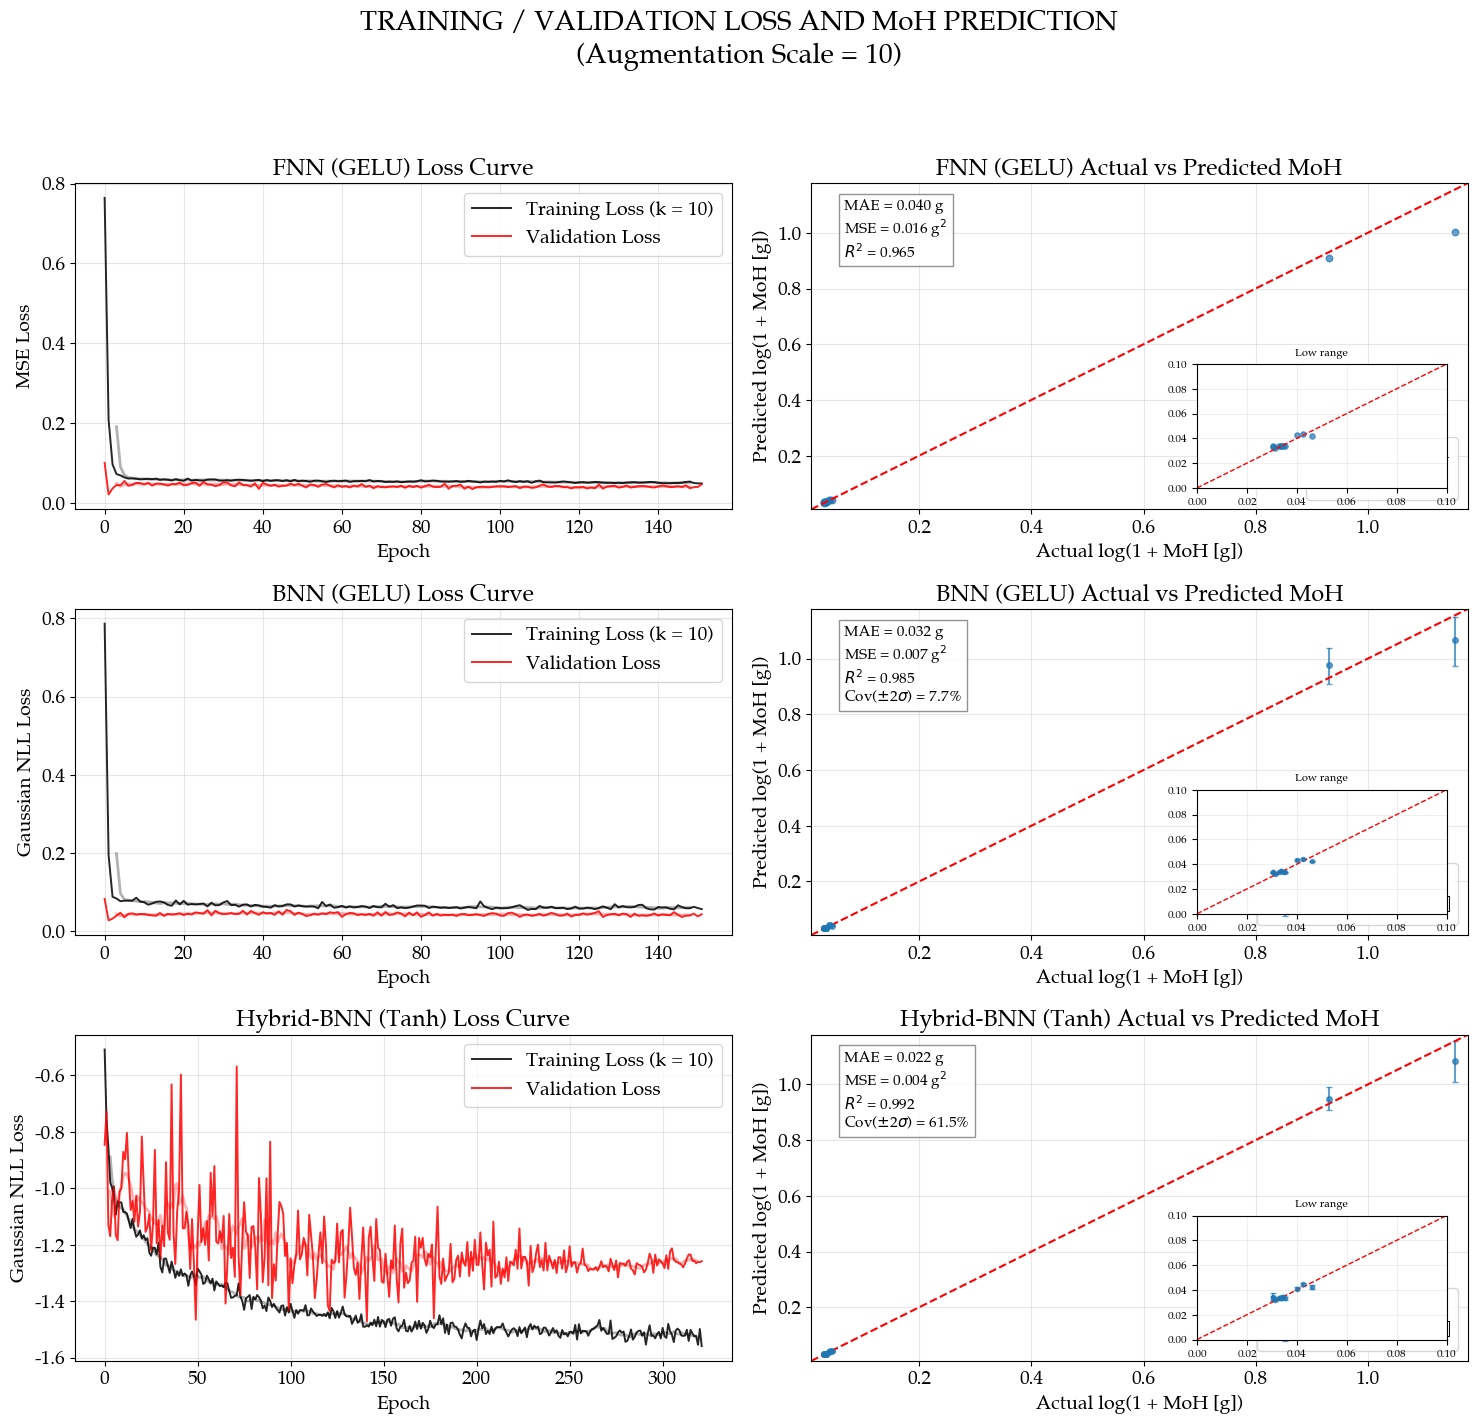


Saved figure: Model_Comparison_Plots_k10_final.png


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from mpl_toolkits.axes_grid1.inset_locator import inset_axes


# Optional custom font
font_path = "/content/Palatia.ttf"

if os.path.exists(font_path):
    fm.fontManager.addfont(font_path)
    prop = fm.FontProperties(fname=font_path)
    font_name = prop.get_name()
    plt.rcParams["font.family"] = font_name
    print(f"Custom font loaded: {font_name}")
else:
    print("Custom font not found — using matplotlib default.")

plt.rcParams["font.size"] = 14
plt.rcParams["font.weight"] = "normal"
plt.rcParams["text.usetex"] = False
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"


# Inputs expected from earlier blocks
models = ["FNN", "BNN", "Hybrid-BNN"]

train_losses_dict = {
    "FNN": fnn_train_losses,
    "BNN": bnn_train_losses,
    "Hybrid-BNN": hybrid_train_losses,
}

val_losses_dict = {
    "FNN": fnn_val_losses,
    "BNN": bnn_val_losses,
    "Hybrid-BNN": hybrid_val_losses,
}

results_dict = {
    "FNN": fnn_results,
    "BNN": bnn_results,
    "Hybrid-BNN": hybrid_results,
}

loss_type_label = {
    "FNN": "MSE Loss",
    "BNN": "Gaussian NLL Loss",
    "Hybrid-BNN": "Gaussian NLL Loss",
}

Z_SIGMA = 2.0

# Helpers function
def moving_average(arr, window=7):
    arr = np.asarray(arr, dtype=float)
    if len(arr) < window:
        return np.arange(len(arr)), arr
    kernel = np.ones(window) / window
    smoothed = np.convolve(arr, kernel, mode="valid")
    x_start = window // 2
    x_idx = np.arange(x_start, x_start + len(smoothed))
    return x_idx, smoothed


def safe_log1p(arr):
    arr = np.asarray(arr, dtype=float)
    return np.log1p(np.clip(arr, a_min=0.0, a_max=None))


def resolve_activation(model_name, preferred=None):
    result_block = results_dict[model_name]
    if preferred is not None and preferred in result_block:
        return preferred

    sample_key = next(iter(result_block))
    sample_result = result_block[sample_key]

    if "val_mae_g" in sample_result:
        return min(result_block, key=lambda a: result_block[a]["val_mae_g"])

    if model_name == "Hybrid-BNN" and "best_hybrid_act" in globals() and best_hybrid_act in result_block:
        return best_hybrid_act

    if "BEST_ACTIVATION" in globals() and BEST_ACTIVATION in result_block:
        return BEST_ACTIVATION

    return max(result_block, key=lambda a: result_block[a].get("r2", -np.inf))


def get_prediction_interval(result, z=Z_SIGMA):
    if "y_std" not in result:
        return None, None, "Predicted"

    y_pred = np.asarray(result["y_pred"], dtype=float).reshape(-1)
    y_std = np.asarray(result["y_std"], dtype=float).reshape(-1)

    lower = np.clip(y_pred - z * y_std, a_min=0.0, a_max=None)
    upper = np.clip(y_pred + z * y_std, a_min=0.0, a_max=None)

    return lower, upper, f"Prediction ±{int(z)}σ"


def build_annotation(model_name, result):
    mae = float(result["mae"])
    mse = float(result["mse"])
    r2 = float(result["r2"])

    lines = [
        f"MAE = {mae:.3f} g",
        f"MSE = {mse:.3f} g$^2$",
        f"$R^2$ = {r2:.3f}",
    ]

    if model_name in {"BNN", "Hybrid-BNN"} and "coverage_95(%)" in result:
        lines.append(f"Cov($\\pm${int(Z_SIGMA)}$\\sigma$) = {float(result['coverage_95(%)']):.1f}%")

    return "\n".join(lines)


# Activation selection
activations = {
    "FNN": resolve_activation("FNN", preferred=BEST_ACTIVATION if "BEST_ACTIVATION" in globals() else None),
    "BNN": resolve_activation("BNN", preferred=BEST_ACTIVATION if "BEST_ACTIVATION" in globals() else None),
    "Hybrid-BNN": resolve_activation("Hybrid-BNN", preferred=best_hybrid_act if "best_hybrid_act" in globals() else None),
}

print("\nSelected activations for plotting:")
for model in models:
    print(f"  {model}: {activations[model]}")


# Shared plot settings
LOW_REGION_MAX = 0.10
SMOOTH_WINDOW = 7

all_x_plot = []
all_y_plot = []
for model in models:
    act = activations[model]
    y_true_global = np.asarray(results_dict[model][act]["y_true"], dtype=float).reshape(-1)
    y_pred_global = np.asarray(results_dict[model][act]["y_pred"], dtype=float).reshape(-1)
    all_x_plot.append(safe_log1p(y_true_global))
    all_y_plot.append(safe_log1p(y_pred_global))

global_min = min(arr.min() for arr in all_x_plot + all_y_plot)
global_max = max(arr.max() for arr in all_x_plot + all_y_plot)

pad = 0.02 * max(global_max - global_min, 1e-6)
axis_min = max(0.0, global_min - pad)
axis_max = global_max + pad


# Figure function
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(15, 15))
fig.suptitle(
    f"TRAINING / VALIDATION LOSS AND MoH PREDICTION\n(Augmentation Scale = {AUG_SCALE})",
    fontsize=20,
)


# Plot loop
for idx, model in enumerate(models):
    act = activations[model]
    result = results_dict[model][act]


    # LEFT: LOSS CURVES
    ax1 = axes[idx, 0]

    train_loss = np.asarray(train_losses_dict[model][act], dtype=float)
    val_loss = np.asarray(val_losses_dict[model][act], dtype=float)
    epochs = np.arange(len(train_loss))

    ax1.plot(
        epochs,
        train_loss,
        color="black",
        linewidth=1.4,
        alpha=0.85,
        label=f"Training Loss (k = {AUG_SCALE})",
    )
    ax1.plot(
        epochs,
        val_loss,
        color="red",
        linewidth=1.4,
        alpha=0.85,
        label="Validation Loss",
    )

    x_smooth, train_smooth = moving_average(train_loss, SMOOTH_WINDOW)
    _, val_smooth = moving_average(val_loss, SMOOTH_WINDOW)

    ax1.plot(x_smooth, train_smooth, color="black", linewidth=2.0, alpha=0.30)
    ax1.plot(x_smooth, val_smooth, color="red", linewidth=2.0, alpha=0.30)

    ax1.set_title(f"{model} ({act}) Loss Curve")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel(loss_type_label[model])
    ax1.legend()
    ax1.grid(True, alpha=0.3)


    # RIGHT: ACTUAL VS PREDICTED
    ax2 = axes[idx, 1]

    y_true = np.asarray(result["y_true"], dtype=float).reshape(-1)
    y_pred = np.asarray(result["y_pred"], dtype=float).reshape(-1)

    x_plot = safe_log1p(y_true)
    y_plot = safe_log1p(y_pred)

    lower, upper, pred_label = get_prediction_interval(result, z=Z_SIGMA)

    if lower is not None and upper is not None:
        lower_log = safe_log1p(lower)
        upper_log = safe_log1p(upper)
        lower_err = np.clip(y_plot - lower_log, a_min=0.0, a_max=None)
        upper_err = np.clip(upper_log - y_plot, a_min=0.0, a_max=None)
        yerr_asym = np.vstack([lower_err, upper_err])

        ax2.errorbar(
            x_plot,
            y_plot,
            yerr=yerr_asym,
            fmt="o",
            markersize=4,
            alpha=0.7,
            capsize=2,
            label=pred_label,
        )
    else:
        ax2.scatter(x_plot, y_plot, s=22, alpha=0.7, label=pred_label)

    ax2.plot(
        [axis_min, axis_max],
        [axis_min, axis_max],
        "r--",
        linewidth=1.5,
        label="Ideal",
    )

    annotation = build_annotation(model, result)
    ax2.text(
        0.05,
        0.95,
        annotation,
        transform=ax2.transAxes,
        fontsize=11,
        verticalalignment="top",
        bbox=dict(facecolor="white", alpha=0.85, edgecolor="gray"),
    )

    ax2.set_title(f"{model} ({act}) Actual vs Predicted MoH")
    ax2.set_xlabel("Actual log(1 + MoH [g])")
    ax2.set_ylabel("Predicted log(1 + MoH [g])")
    ax2.set_xlim(axis_min, axis_max)
    ax2.set_ylim(axis_min, axis_max)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    # INSET: LOW RANGE IN ORIGINAL UNITS
    low_mask = y_true <= LOW_REGION_MAX

    if np.sum(low_mask) >= 2:
        axins = inset_axes(ax2, width="38%", height="38%", loc="lower right", borderpad=1.1)

        if lower is not None and upper is not None:
            low_true = y_true[low_mask]
            low_pred = y_pred[low_mask]
            low_lower = lower[low_mask]
            low_upper = upper[low_mask]
            low_yerr = np.vstack([
                np.clip(low_pred - low_lower, a_min=0.0, a_max=None),
                np.clip(low_upper - low_pred, a_min=0.0, a_max=None),
            ])

            axins.errorbar(
                low_true,
                low_pred,
                yerr=low_yerr,
                fmt="o",
                markersize=3,
                alpha=0.7,
                capsize=2,
            )
        else:
            axins.scatter(y_true[low_mask], y_pred[low_mask], s=14, alpha=0.7)

        low_max = max(
            LOW_REGION_MAX,
            y_true[low_mask].max() * 1.05,
            y_pred[low_mask].max() * 1.05,
        )

        if lower is not None and upper is not None:
            low_max = max(low_max, upper[low_mask].max() * 1.05)

        axins.plot([0.0, low_max], [0.0, low_max], "r--", linewidth=1.0)
        axins.set_xlim(0.0, low_max)
        axins.set_ylim(0.0, low_max)
        axins.set_title("Low range", fontsize=8)
        axins.tick_params(axis="both", labelsize=8)
        axins.grid(True, alpha=0.2)


# Final layout and save
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
output_path = f"Model_Comparison_Plots_k{AUG_SCALE}_final.png"
plt.savefig(output_path, dpi=600, bbox_inches="tight")
plt.show()

print(f"\nSaved figure: {output_path}")